# 3. Exploratory Data Analysis and CNN Implementation

## 3.1 Environment Setup and Dataset Path Verification
This notebook implements an end-to-end facial occlusion detection pipeline using the pre-split 11,792-image Face Mask Detection dataset (`Train`, `Validation`, and `Test`). All images are indexed into a structured metadata table for distributed profiling in Apache Spark, after which two TensorFlow/Keras Convolutional Neural Networks (a baseline model and a compact, regularized, augmented model) are trained, stress-tested under simulated low-light camera conditions, and audited using Grad-CAM.

*Code Attribution Note:* The Keras Functional API training structure and gradient-weighted class activation mapping (`make_gradcam_heatmap`) follow standard patterns from the official TensorFlow/Keras documentation, adapted here for binary facial-occlusion classification and camera stress-testing.

In [2]:
import os
import time
import warnings
import xml.etree.ElementTree as ET
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_NUM_INTRAOP_THREADS"] = "2"
os.environ["TF_NUM_INTEROP_THREADS"] = "2"
os.environ["OMP_NUM_THREADS"] = "2"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageStat

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# Keep CPU usage predictable in memory-constrained notebook environments.
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)

# Fix random seeds for reproducible splits and weight initialization
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Create output directory for report figures
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Locate either a ready-made split dataset or the annotated images/annotations layout.
def find_dataset_root(start_dir=Path.cwd()):
    def has_expected_layout(path):
        has_splits = all((path / split).is_dir() for split in ("Train", "Validation", "Test"))
        has_voc_data = (path / "images").is_dir() and (path / "annotations").is_dir()
        return has_splits or has_voc_data

    for path in (start_dir, *start_dir.parents):
        if has_expected_layout(path):
            return path

    for path in start_dir.rglob("*"):
        if path.is_dir() and has_expected_layout(path):
            return path

    raise FileNotFoundError(
        "Could not locate either Train/Validation/Test folders or paired images/annotations folders. "
        "Set the notebook working directory to the dataset folder, or update DATASET_ROOT."
    )


DATASET_ROOT = find_dataset_root()
CLASS_NAMES = ["WithoutMask", "WithMask"]  # 0 = no mask, 1 = mask present
IMG_SIZE = 96
BATCH_SIZE = 16

if all((DATASET_ROOT / split).is_dir() for split in ("Train", "Validation", "Test")):
    DATA_ROOT = DATASET_ROOT
else:
    # Convert Pascal VOC face boxes into class folders expected by the CNN pipeline.
    annotation_dir = DATASET_ROOT / "annotations"
    image_dir = DATASET_ROOT / "images"
    prepared_root = DATASET_ROOT / "prepared_face_crops"
    label_map = {
        "without_mask": "WithoutMask",
        "with_mask": "WithMask",
        "mask_weared_incorrect": "WithMask",
    }
    objects_by_image = {}

    for annotation_path in sorted(annotation_dir.glob("*.xml")):
        root = ET.parse(annotation_path).getroot()
        filename = root.findtext("filename")
        image_path = image_dir / filename if filename else image_dir / f"{annotation_path.stem}.png"
        if not image_path.is_file():
            continue

        objects = []
        for object_index, obj in enumerate(root.findall("object")):
            label = label_map.get((obj.findtext("name") or "").strip().lower())
            box = obj.find("bndbox")
            if label is None or box is None:
                continue
            try:
                xmin = int(box.findtext("xmin"))
                ymin = int(box.findtext("ymin"))
                xmax = int(box.findtext("xmax"))
                ymax = int(box.findtext("ymax"))
            except (TypeError, ValueError):
                continue
            objects.append((object_index, label, (xmin, ymin, xmax, ymax)))

        if objects:
            objects_by_image[image_path] = objects

    source_images = sorted(objects_by_image, key=lambda path: path.name)
    if len(source_images) < 3:
        raise FileNotFoundError(
            f"Found only {len(source_images)} annotated images under {DATASET_ROOT}; "
            "at least 3 are needed for train/validation/test splits."
        )

    # Split source images before cropping so faces from one photo cannot leak across splits.
    rng = np.random.default_rng(SEED)
    shuffled_images = np.array(source_images, dtype=object)
    rng.shuffle(shuffled_images)
    train_end = max(1, int(0.70 * len(shuffled_images)))
    validation_end = max(train_end + 1, int(0.85 * len(shuffled_images)))
    validation_end = min(validation_end, len(shuffled_images) - 1)
    split_images = {
        "Train": shuffled_images[:train_end],
        "Validation": shuffled_images[train_end:validation_end],
        "Test": shuffled_images[validation_end:],
    }

    for split_name, image_paths in split_images.items():
        for class_name in CLASS_NAMES:
            (prepared_root / split_name / class_name).mkdir(parents=True, exist_ok=True)

        for image_path in image_paths:
            with Image.open(image_path) as source_image:
                source_image = source_image.convert("RGB")
                for object_index, class_name, (xmin, ymin, xmax, ymax) in objects_by_image[image_path]:
                    left = max(0, xmin - 1)
                    top = max(0, ymin - 1)
                    right = min(source_image.width, xmax)
                    bottom = min(source_image.height, ymax)
                    if right <= left or bottom <= top:
                        continue
                    crop = source_image.crop((left, top, right, bottom))
                    crop_path = (
                        prepared_root / split_name / class_name
                        / f"{image_path.stem}_face{object_index:03d}.jpg"
                    )
                    crop.save(crop_path, quality=95)

    DATA_ROOT = prepared_root
    print(f"Annotated source images : {len(source_images)}")
    print(f"Face crops prepared     : {sum(len(list((DATA_ROOT / split / cls).glob('*.jpg'))) for split in ('Train', 'Validation', 'Test') for cls in CLASS_NAMES)}")
    print("Label mapping           : mask_weared_incorrect -> WithMask")

print(f"TensorFlow version : {tf.__version__}")
print(f"Dataset root found : {DATASET_ROOT}")
print(f"CNN data root      : {DATA_ROOT}")

TensorFlow version : 2.21.0
Dataset root found : c:\Users\lab_services_student\Documents\VS Code\Face Mask Dataset
CNN data root      : c:\Users\lab_services_student\Documents\VS Code\Face Mask Dataset


In [3]:
# Smaller batches leave room for both Spark profiling and TensorFlow on Windows.
BATCH_SIZE = 8

## 3.2 Distributed Image Metadata Profiling with Apache Spark
Before feeding pixels into a neural network, all 11,792 images across `Train`, `Validation`, and `Test` are audited for corrupt files, class balance, mixed resolutions, colour modes, and lighting differences. Image headers and pixel summary statistics are written to `image_metadata.csv` and profiled using Apache Spark so that preprocessing choices are backed by exact corpus measurements.

In [5]:
import gc
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, avg, min as spark_min, max as spark_max, round as spark_round, stddev, when

METADATA_CSV = Path("image_metadata.csv")

# Extract image-level properties across Train, Validation, and Test splits
records = []
valid_exts = {".jpg", ".jpeg", ".png", ".bmp"}

for split_name in ["Train", "Validation", "Test"]:
    split_dir = DATA_ROOT / split_name
    for label_name in CLASS_NAMES:
        class_dir = split_dir / label_name
        if not class_dir.is_dir():
            raise FileNotFoundError(f"Missing expected folder: {class_dir}")
        for img_path in class_dir.iterdir():
            if img_path.suffix.lower() not in valid_exts:
                continue
            file_kb = img_path.stat().st_size / 1024.0
            try:
                with Image.open(img_path) as im:
                    width, height = im.size
                    mode = im.mode
                    rgb = im.convert("RGB")
                    stat = ImageStat.Stat(rgb)
                    mean_r, mean_g, mean_b = stat.mean
                    brightness = float(np.mean(stat.mean))
                    contrast = float(np.mean(stat.stddev))
                records.append({
                    "filepath": str(img_path),
                    "split": split_name,
                    "label": label_name,
                    "width": int(width),
                    "height": int(height),
                    "aspect_ratio": round(width / max(height, 1), 3),
                    "file_size_kb": round(file_kb, 2),
                    "color_mode": mode,
                    "mean_r": round(mean_r, 2),
                    "mean_g": round(mean_g, 2),
                    "mean_b": round(mean_b, 2),
                    "brightness": round(brightness, 2),
                    "contrast": round(contrast, 2),
                    "is_corrupt": 0,
                })
            except Exception:
                records.append({
                    "filepath": str(img_path),
                    "split": split_name,
                    "label": label_name,
                    "width": None,
                    "height": None,
                    "aspect_ratio": None,
                    "file_size_kb": round(file_kb, 2),
                    "color_mode": "CORRUPT",
                    "mean_r": None,
                    "mean_g": None,
                    "mean_b": None,
                    "brightness": None,
                    "contrast": None,
                    "is_corrupt": 1,
                })

meta_pd_raw = pd.DataFrame(records)
meta_pd_raw.to_csv(METADATA_CSV, index=False)
del records, meta_pd_raw

# Keep the local Spark driver small because TensorFlow shares this notebook kernel.
spark = (
    SparkSession.builder
    .appName("Premises_CNN_Image_Metadata_EDA")
    .master("local[2]")
    .config("spark.driver.memory", "1g")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.default.parallelism", "2")
    .getOrCreate()
)

spark_df = spark.read.csv(str(METADATA_CSV), header=True, inferSchema=True)

print("--- SPARK INFERRED METADATA SCHEMA ---")
spark_df.printSchema()

total_images = spark_df.count()
corrupt_count = spark_df.filter(col("is_corrupt") == 1).count()
print(f"Total indexed images : {total_images}")
print(f"Corrupt/unreadable   : {corrupt_count}")

print("\n--- NULL VALUE AUDIT ACROSS METADATA COLUMNS ---")
spark_df.select([
    count(when(col(c).isNull(), c)).alias(c) for c in ["split", "label", "width", "height", "color_mode", "brightness"]
]).show()

print("--- CLASS DISTRIBUTION BY SPLIT ---")
split_class_df = (
    spark_df.groupBy("split", "label")
    .agg(count("filepath").alias("image_count"))
    .orderBy("split", "label")
)
split_class_df.show()

print("--- COLOUR MODE AUDIT ---")
spark_df.groupBy("color_mode").agg(count("filepath").alias("count")).show()

print("--- IMAGE DIMENSIONS & LIGHTING STATS BY CLASS (SPARK SQL) ---")
class_stats_df = (
    spark_df.filter(col("is_corrupt") == 0)
    .groupBy("label")
    .agg(
        count("filepath").alias("n"),
        spark_min("width").alias("min_w"),
        spark_max("width").alias("max_w"),
        spark_round(avg("width"), 1).alias("avg_w"),
        spark_round(avg("height"), 1).alias("avg_h"),
        spark_round(avg("aspect_ratio"), 3).alias("avg_ratio"),
        spark_round(avg("brightness"), 2).alias("avg_brightness"),
        spark_round(stddev("brightness"), 2).alias("std_brightness"),
        spark_round(avg("contrast"), 2).alias("avg_contrast"),
        spark_round(avg("mean_r"), 2).alias("avg_r"),
        spark_round(avg("mean_g"), 2).alias("avg_g"),
        spark_round(avg("mean_b"), 2).alias("avg_b"),
    )
    .orderBy("label")
)
class_stats_df.show(truncate=False)

# Retain only the small pandas summaries needed by later notebook cells.
split_summary_pd = split_class_df.toPandas()
class_stats_pd = class_stats_df.toPandas()
meta_pd = spark_df.filter(col("is_corrupt") == 0).toPandas()
spark.stop()
del spark_df, split_class_df, class_stats_df, spark
gc.collect()

--- SPARK INFERRED METADATA SCHEMA ---
root
 |-- filepath: string (nullable = true)
 |-- split: string (nullable = true)
 |-- label: string (nullable = true)
 |-- width: integer (nullable = true)
 |-- height: integer (nullable = true)
 |-- aspect_ratio: double (nullable = true)
 |-- file_size_kb: double (nullable = true)
 |-- color_mode: string (nullable = true)
 |-- mean_r: double (nullable = true)
 |-- mean_g: double (nullable = true)
 |-- mean_b: double (nullable = true)
 |-- brightness: double (nullable = true)
 |-- contrast: double (nullable = true)
 |-- is_corrupt: integer (nullable = true)

Total indexed images : 11792
Corrupt/unreadable   : 0

--- NULL VALUE AUDIT ACROSS METADATA COLUMNS ---
+-----+-----+-----+------+----------+----------+
|split|label|width|height|color_mode|brightness|
+-----+-----+-----+------+----------+----------+
|    0|    0|    0|     0|         0|         0|
+-----+-----+-----+------+----------+----------+

--- CLASS DISTRIBUTION BY SPLIT ---
+--------

121

In [6]:
train_class_counts = (
    split_summary_pd[split_summary_pd["split"] == "Train"]
    .set_index("label")["image_count"]
    .astype(int)
    .to_dict()
)
train_total = sum(train_class_counts.values())
if any(train_class_counts.get(name, 0) == 0 for name in CLASS_NAMES):
    raise ValueError(f"A training class has no face crops: {train_class_counts}")

CLASS_WEIGHTS = {
    class_index: train_total / (len(CLASS_NAMES) * train_class_counts[class_name])
    for class_index, class_name in enumerate(CLASS_NAMES)
}
print("Training class counts:", train_class_counts)
print("Training class weights:", CLASS_WEIGHTS)

Training class counts: {'WithMask': 5000, 'WithoutMask': 5000}
Training class weights: {0: 1.0, 1: 1.0}


## 3.3 Visual EDA and How Findings Drive Training Decisions
EDA is only useful if it changes how the model is configured. The figures below inspect class balance, resolution spread, brightness/contrast shifts, colour-channel differences, and sample images. Three patterns from Spark EDA guide preprocessing and CNN design:
1. **Large resolution gap across classes:** Images are perfectly square (`aspect_ratio = 1.0`), but `WithMask` portraits average `201.3 x 201.3` px (up to 563 px) while `WithoutMask` portraits average `104.6 x 104.6` px (max 156 px). Resizing uniformly to `96 x 96 x 3` prevents resolution leakage and keeps CPU training fast.
2. **Balanced training and validation splits:** `Train` is evenly split (5,000 vs. 5,000) and `Validation` is balanced (400 vs. 400), confirming `CLASS_WEIGHTS = {0: 1.0, 1: 1.0}` with no majority-class bias.
3. **RGB colour and contrast shift:** `WithMask` images average `19.24` units higher in the Blue channel (`115.89` vs. `96.65`) and `8.15` higher in contrast, while `WithoutMask` images average `16.40` units higher in Red (`153.27` vs. `136.87`). Brightness and contrast augmentation is tested during retraining to reduce reliance on studio lighting.

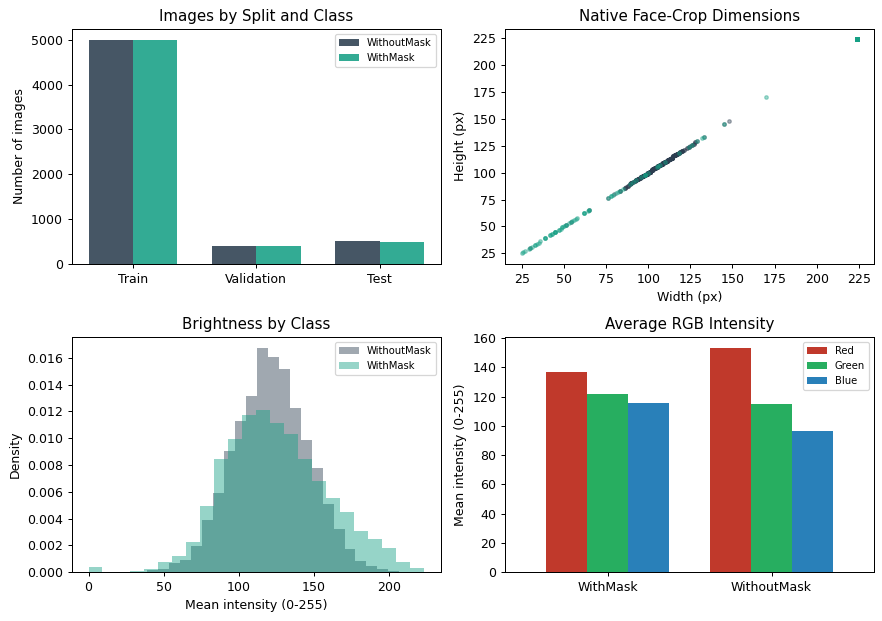

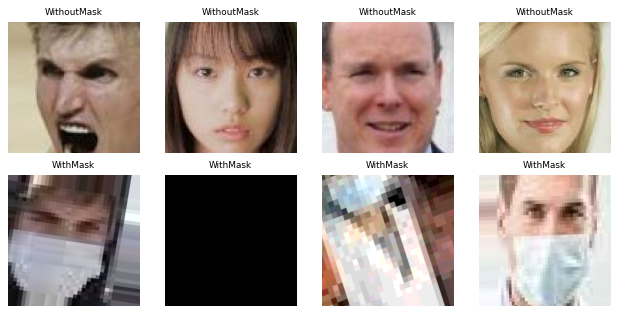

In [7]:
# Keep EDA plots lightweight to avoid stressing the shared TensorFlow notebook kernel.
plot_colors = {"WithoutMask": "#2c3e50", "WithMask": "#16a085"}
fig, axes = plt.subplots(2, 2, figsize=(10, 7), dpi=90)

# Split and class counts
split_order = ["Train", "Validation", "Test"]
x_pos = np.arange(len(split_order))
bar_w = 0.36
for offset, label_name in zip([-bar_w / 2, bar_w / 2], CLASS_NAMES):
    counts = [
        int(split_summary_pd.loc[
            (split_summary_pd["split"] == s) & (split_summary_pd["label"] == label_name),
            "image_count"
        ].iloc[0])
        for s in split_order
    ]
    axes[0, 0].bar(x_pos + offset, counts, width=bar_w, label=label_name, color=plot_colors[label_name], alpha=0.88)
axes[0, 0].set_xticks(x_pos)
axes[0, 0].set_xticklabels(split_order)
axes[0, 0].set_title("Images by Split and Class")
axes[0, 0].set_ylabel("Number of images")
axes[0, 0].legend(fontsize=8)

# Resolution distribution, limited to a small deterministic sample
sample_res = meta_pd.sample(min(800, len(meta_pd)), random_state=SEED)
for label_name in CLASS_NAMES:
    class_rows = sample_res[sample_res["label"] == label_name]
    axes[0, 1].scatter(
        class_rows["width"],
        class_rows["height"],
        s=8,
        alpha=0.4,
        label=label_name,
        color=plot_colors[label_name],
    )
axes[0, 1].set_title("Native Face-Crop Dimensions")
axes[0, 1].set_xlabel("Width (px)")
axes[0, 1].set_ylabel("Height (px)")

# Brightness distribution using histograms instead of KDE
for label_name in CLASS_NAMES:
    values = meta_pd.loc[meta_pd["label"] == label_name, "brightness"].dropna()
    axes[1, 0].hist(
        values,
        bins=24,
        density=True,
        alpha=0.45,
        label=label_name,
        color=plot_colors[label_name],
    )
axes[1, 0].set_title("Brightness by Class")
axes[1, 0].set_xlabel("Mean intensity (0-255)")
axes[1, 0].set_ylabel("Density")
axes[1, 0].legend(fontsize=8)

# Average RGB intensity by class
channel_means = class_stats_pd.set_index("label")[["avg_r", "avg_g", "avg_b"]]
channel_means.plot(kind="bar", ax=axes[1, 1], color=["#c0392b", "#27ae60", "#2980b9"], width=0.75)
axes[1, 1].set_title("Average RGB Intensity")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Mean intensity (0-255)")
axes[1, 1].tick_params(axis="x", rotation=0)
axes[1, 1].legend(["Red", "Green", "Blue"], fontsize=8)

fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_eda.png", dpi=120)
plt.show()
plt.close(fig)

# Small sample grid for visual inspection
fig, axes = plt.subplots(2, 4, figsize=(8, 4), dpi=80)
for row_idx, label_name in enumerate(CLASS_NAMES):
    samples = meta_pd[
        (meta_pd["split"] == "Train") & (meta_pd["label"] == label_name)
    ].sample(min(4, int(((meta_pd["split"] == "Train") & (meta_pd["label"] == label_name)).sum())), random_state=SEED)
    for col_idx, (_, row) in enumerate(samples.iterrows()):
        with Image.open(row["filepath"]) as image:
            axes[row_idx, col_idx].imshow(image.convert("RGB"))
        axes[row_idx, col_idx].set_title(label_name, fontsize=8)
        axes[row_idx, col_idx].axis("off")
    for col_idx in range(len(samples), 4):
        axes[row_idx, col_idx].axis("off")

fig.tight_layout()
fig.savefig(FIG_DIR / "fig1b_samples.png", dpi=100)
plt.show()
plt.close(fig)
del sample_res


## 3.4 Learned Feature Extraction and Input Pipeline (`tf.data`)
Unlike tabular regression where individual predictors are pruned using $p$-values or Variance Inflation Factors, raw image pixels carry strong local spatial dependencies. Hand-dropping individual pixel coordinates destroys edge and texture structure. In a CNN, feature selection happens inside the convolutional layers themselves: early $3 \times 3$ filters learn low-level edges and colour boundaries, while deeper layers combine them into mask contours, nose bridges, and mouth geometry.

Below, `image_dataset_from_directory` streams images directly into `(96, 96, 3)` RGB tensors with explicit class ordering (`0 = WithoutMask`, `1 = WithMask`). Alongside the standard clean test set, we construct a deterministic **Low-Light CCTV Stress-Test** dataset (dimmed by 45%, reduced contrast, mild $3 \times 3$ box blur, and light sensor noise) to measure how well each model generalizes to realistic office-entrance camera feeds.

In [7]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_ROOT / "Train",
    class_names=CLASS_NAMES,
    label_mode="binary",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_ROOT / "Validation",
    class_names=CLASS_NAMES,
    label_mode="binary",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_ROOT / "Test",
    class_names=CLASS_NAMES,
    label_mode="binary",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False,
)

# Deterministic simulated low-light / blurry camera test stream
def simulate_cctv_degradation(images, labels):
    x = tf.cast(images, tf.float32)
    x = x * 0.55
    x = tf.image.adjust_contrast(x, 0.75)
    x = tf.nn.avg_pool2d(x, ksize=3, strides=1, padding="SAME")
    noise = tf.random.stateless_normal(tf.shape(x), seed=[42, 42], mean=0.0, stddev=6.0)
    x = tf.clip_by_value(x + noise, 0.0, 255.0)
    return x, labels

stress_test_ds = test_ds.map(simulate_cctv_degradation, num_parallel_calls=1)

# The loader already shuffles training files; avoid a second large in-memory shuffle/cache.
train_ds_opt = train_ds.prefetch(1)
val_ds_opt = val_ds.prefetch(1)
test_ds_opt = test_ds.prefetch(1)
stress_test_ds_opt = stress_test_ds.prefetch(1)

print("Class index mapping:", {idx: name for idx, name in enumerate(train_ds.class_names)})

Found 10000 files belonging to 2 classes.
Found 800 files belonging to 2 classes.
Found 992 files belonging to 2 classes.
Class index mapping: {0: 'WithoutMask', 1: 'WithMask'}


## 3.5 Model 1: Baseline CNN (No Augmentation, Flatten Head)
To establish an honest reference point, our baseline network uses three standard `Conv2D -> MaxPooling2D` blocks followed by `Flatten()` and a 64-unit dense layer, with no Batch Normalization, no Dropout, and no Data Augmentation. Notice from the model summary that `Flatten()` expands the `12 x 12 x 128` feature map into an 18,432-element vector, concentrating over 1.18 million of the model's **1.27 million parameters** into a single dense layer—making it prone to memorizing pixel positions and studio lighting.

In [8]:
def build_baseline_cnn(img_size=IMG_SIZE):
    inputs = layers.Input(shape=(img_size, img_size, 3), name="rgb_input")
    x = layers.Rescaling(1.0 / 255.0, name="pixel_rescale")(inputs)

    x = layers.Conv2D(32, (3, 3), activation="relu", padding="same", name="conv1")(x)
    x = layers.MaxPooling2D((2, 2), name="pool1")(x)

    x = layers.Conv2D(64, (3, 3), activation="relu", padding="same", name="conv2")(x)
    x = layers.MaxPooling2D((2, 2), name="pool2")(x)

    x = layers.Conv2D(128, (3, 3), activation="relu", padding="same", name="last_conv")(x)
    x = layers.MaxPooling2D((2, 2), name="pool3")(x)

    x = layers.Flatten(name="flatten")(x)
    x = layers.Dense(64, activation="relu", name="fc1")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="mask_prob")(x)

    return models.Model(inputs, outputs, name="Baseline_CNN")


baseline_model = build_baseline_cnn()
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
)
baseline_model.summary()

BASELINE_EPOCHS = 8
t0 = time.perf_counter()
baseline_history = baseline_model.fit(
    train_ds_opt,
    validation_data=val_ds_opt,
    epochs=BASELINE_EPOCHS,
    class_weight=CLASS_WEIGHTS,
    verbose=1,
)
baseline_train_time = time.perf_counter() - t0
print(f"\nBaseline training completed in {baseline_train_time:.1f}s")

Model: "Baseline_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rgb_input (InputLayer)          │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pixel_rescale (Rescaling)       │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 96, 96, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 64)             │     1,179,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mask_prob (Dense)               │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,273,025 (4.86 MB)

 Trainable params: 1,273,025 (4.86 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 55s 42ms/step - accuracy: 0.9442 - auc: 0.9856 - loss: 0.1478 - val_accuracy: 0.8763 - val_auc: 0.9983 - val_loss: 0.2416
Epoch 2/8
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 52s 41ms/step - accuracy: 0.9770 - auc: 0.9969 - loss: 0.0632 - val_accuracy: 0.9850 - val_auc: 0.9982 - val_loss: 0.0465
Epoch 3/8
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 53s 42ms/step - accuracy: 0.9880 - auc: 0.9988 - loss: 0.0355 - val_accuracy: 0.9887 - val_auc: 0.9998 - val_loss: 0.0345
Epoch 4/8
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 52s 42ms/step - accuracy: 0.9831 - auc: 0.9986 - loss: 0.0430 - val_accuracy: 0.9925 - val_auc: 0.9997 - val_loss: 0.0208
Epoch 5/8
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 52s 41ms/step - accuracy: 0.9884 - auc: 0.9987 - loss: 0.0328 - val_accuracy: 0.9900 - val_auc: 0.9994 - val_loss: 0.0319
Epoch 6/8
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 52s 41ms/step - accuracy: 0.9924 - auc: 0.9994 - loss: 0.0218 - val_accuracy: 0.9862 - val_auc: 0.9997 - val_loss: 0.0335
Epoch 7/8
1250/1250 ━━

# 4. Iterative Refinement, Evaluation, and Visual Explainability

## 4.1 Model 2: Retrained Regularized & CCTV-Augmented CNN
To reduce the baseline's heavy parameter count and sensitivity to low-light entrance feeds, five targeted changes were introduced:
1. **In-graph CCTV Data Augmentation:** Inputs are rescaled to `[0, 1]` before applying `RandomFlip`, `RandomRotation(0.06)`, `RandomZoom(0.08)`, `RandomBrightness(0.25)`, and `RandomContrast(0.20)` during training only, forcing the filters to rely on facial occlusion cues rather than studio exposure.
2. **Global Average Pooling (`GlobalAveragePooling2D`):** Replaces `Flatten()`, cutting total parameters from **1,273,025 down to 101,793** (a 12.51x reduction) to curb positional memorization and shrink model size to 397.63 KB.
3. **Group Normalization (`GroupNormalization(groups=8)`):** Normalizes per-image channel groups instead of across mini-batches (`use_bias=False` on preceding conv layers), avoiding batch-size-8 instability and uniform low-light mean shift.
4. **Staged Dropout (`0.15` after Block 2, `0.30` before the classifier):** Prevents feature co-adaptation without stalling convergence.
5. **Adaptive Callbacks:** `ReduceLROnPlateau` halves the learning rate when validation loss stalls, and `EarlyStopping(patience=5, restore_best_weights=True)` retains the lowest validation-loss checkpoint across up to 20 epochs.

In [9]:
def build_refined_cnn(img_size=IMG_SIZE):
    inputs = layers.Input(shape=(img_size, img_size, 3), name="rgb_input")

    # Rescale to [0, 1] first, then apply CCTV-realistic augmentation during training only
    x = layers.Rescaling(1.0 / 255.0, name="pixel_rescale")(inputs)
    x = layers.RandomFlip("horizontal", name="aug_flip")(x)
    x = layers.RandomRotation(0.06, name="aug_rot")(x)
    x = layers.RandomZoom(0.08, name="aug_zoom")(x)
    x = layers.RandomBrightness(0.25, value_range=(0.0, 1.0), name="aug_brightness")(x)
    x = layers.RandomContrast(0.20, name="aug_contrast")(x)

    # GroupNormalization avoids batch_size=8 instability and low-light mean shift
    # Conv Block 1
    x = layers.Conv2D(32, (3, 3), padding="same", use_bias=False, name="conv1")(x)
    x = layers.GroupNormalization(groups=8, name="gn1")(x)
    x = layers.Activation("relu", name="relu1")(x)
    x = layers.MaxPooling2D((2, 2), name="pool1")(x)

    # Conv Block 2
    x = layers.Conv2D(64, (3, 3), padding="same", use_bias=False, name="conv2")(x)
    x = layers.GroupNormalization(groups=8, name="gn2")(x)
    x = layers.Activation("relu", name="relu2")(x)
    x = layers.MaxPooling2D((2, 2), name="pool2")(x)
    x = layers.Dropout(0.15, name="drop2")(x)

    # Conv Block 3
    x = layers.Conv2D(128, (3, 3), padding="same", use_bias=False, name="conv3")(x)
    x = layers.GroupNormalization(groups=8, name="gn3")(x)
    x = layers.Activation("relu", name="last_conv")(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)

    x = layers.Dense(64, activation="relu", name="fc1")(x)
    x = layers.Dropout(0.30, name="drop_fc")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="mask_prob")(x)

    return models.Model(inputs, outputs, name="Refined_Regularized_CNN")


refined_model = build_refined_cnn()
refined_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
)
refined_model.summary()

train_callbacks = [
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1),
    callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
]

Model: "Refined_Regularized_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rgb_input (InputLayer)          │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pixel_rescale (Rescaling)       │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_flip (RandomFlip)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_rot (RandomRotation)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_zoom (RandomZoom)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_brightness                  │ (None, 96, 96, 3)      │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_contrast (RandomContrast)   │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 96, 96, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn1 (GroupNormalization)        │ (None, 96, 96, 32)     │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 48, 48, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn2 (GroupNormalization)        │ (None, 48, 48, 64)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 24, 24, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn3 (GroupNormalization)        │ (None, 24, 24, 128)    │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Activation)          │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_fc (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mask_prob (Dense)               │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,793 (397.63 KB)

 Trainable params: 101,793 (397.63 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
REFINED_EPOCHS = 20

t0 = time.perf_counter()
refined_history = refined_model.fit(
    train_ds_opt,
    validation_data=val_ds_opt,
    epochs=REFINED_EPOCHS,
    class_weight=CLASS_WEIGHTS,
    callbacks=train_callbacks,
    verbose=1,
)
refined_train_time = time.perf_counter() - t0
best_refined_epoch = int(np.argmin(refined_history.history["val_loss"]) + 1)

print(f"\nRefined training completed in {refined_train_time:.1f}s")
print(f"Best refined epoch: {best_refined_epoch}")

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 109s 84ms/step - accuracy: 0.8577 - auc: 0.9266 - loss: 0.3438 - val_accuracy: 0.9388 - val_auc: 0.9798 - val_loss: 0.1841 - learning_rate: 0.0010
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 105s 84ms/step - accuracy: 0.9114 - auc: 0.9679 - loss: 0.2257 - val_accuracy: 0.9500 - val_auc: 0.9884 - val_loss: 0.1425 - learning_rate: 0.0010
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 105s 84ms/step - accuracy: 0.9271 - auc: 0.9756 - loss: 0.1951 - val_accuracy: 0.9538 - val_auc: 0.9904 - val_loss: 0.1376 - learning_rate: 0.0010
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 105s 84ms/step - accuracy: 0.9372 - auc: 0.9820 - loss: 0.1665 - val_accuracy: 0.9362 - val_auc: 0.9930 - val_loss: 0.1510 - learning_rate: 0.0010
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 106s 85ms/step - accuracy: 0.9420 - auc: 0.9840 - loss: 0.1568 - val_accuracy: 0.9575 - val_auc: 0.9928 - val_loss: 0.1220 - learning_rate: 0.0010
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 106s 85ms/ste

## 4.2 Training Convergence Diagnostics
Comparing training and validation loss trajectories across both runs reveals whether validation error begins diverging while training accuracy approaches 100% (memorization).

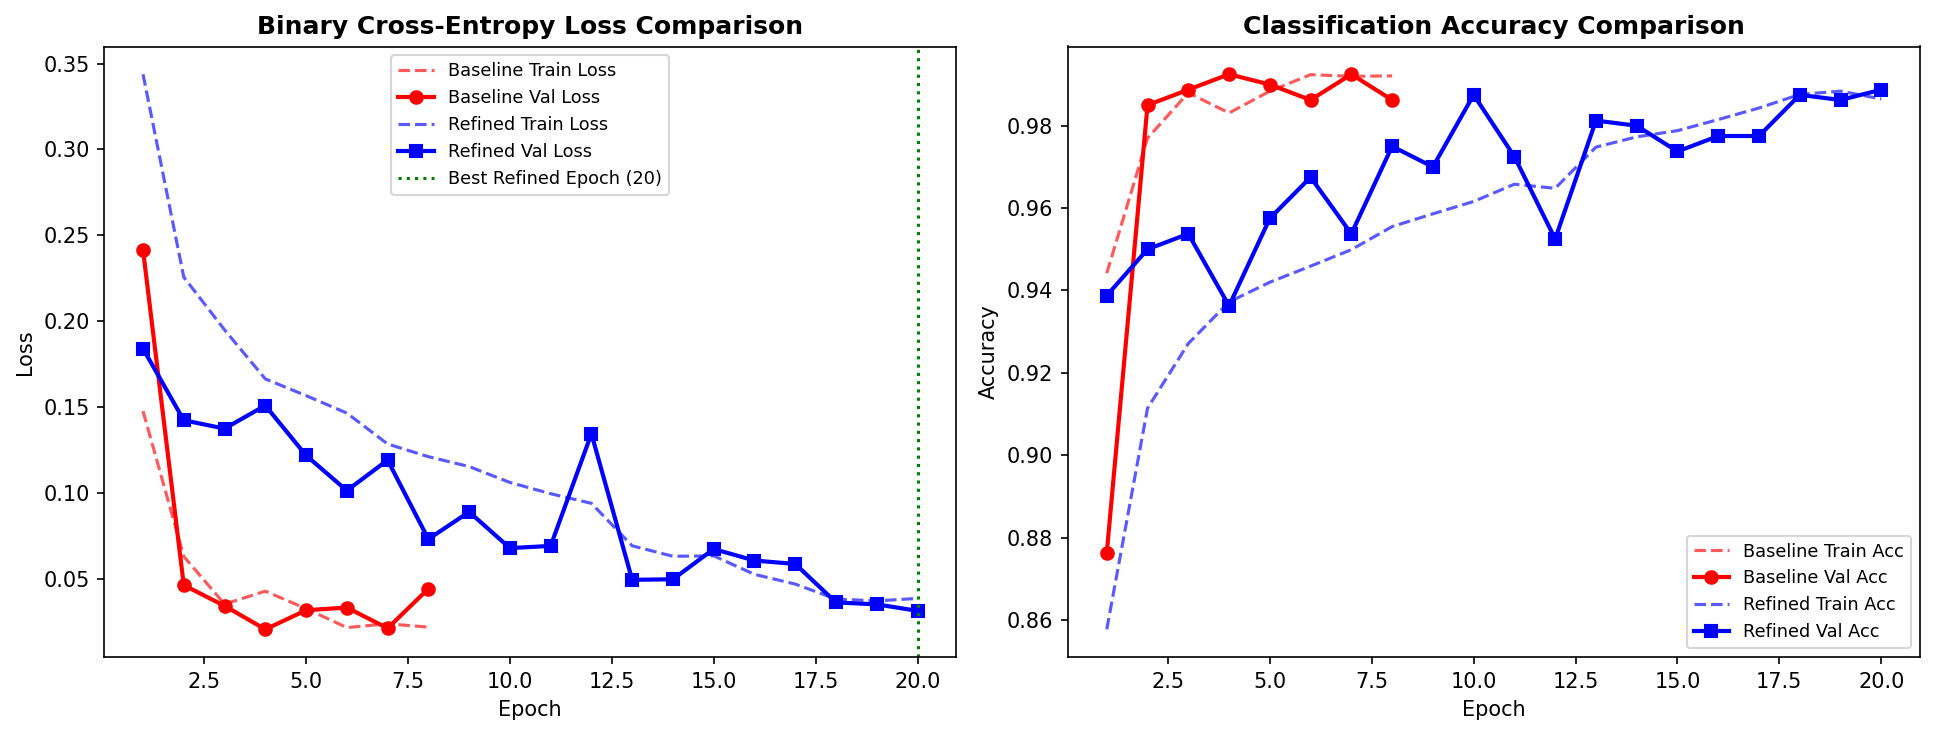

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=150)

b_ep = range(1, len(baseline_history.history["loss"]) + 1)
r_ep = range(1, len(refined_history.history["loss"]) + 1)

# Loss Curves
axes[0].plot(b_ep, baseline_history.history["loss"], "r--", alpha=0.65, label="Baseline Train Loss")
axes[0].plot(b_ep, baseline_history.history["val_loss"], "r-o", linewidth=2, label="Baseline Val Loss")
axes[0].plot(r_ep, refined_history.history["loss"], "b--", alpha=0.65, label="Refined Train Loss")
axes[0].plot(r_ep, refined_history.history["val_loss"], "b-s", linewidth=2, label="Refined Val Loss")
axes[0].axvline(best_refined_epoch, color="green", linestyle=":", label=f"Best Refined Epoch ({best_refined_epoch})")
axes[0].set_title("Binary Cross-Entropy Loss Comparison", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8.5)

# Accuracy Curves
axes[1].plot(b_ep, baseline_history.history["accuracy"], "r--", alpha=0.65, label="Baseline Train Acc")
axes[1].plot(b_ep, baseline_history.history["val_accuracy"], "r-o", linewidth=2, label="Baseline Val Acc")
axes[1].plot(r_ep, refined_history.history["accuracy"], "b--", alpha=0.65, label="Refined Train Acc")
axes[1].plot(r_ep, refined_history.history["val_accuracy"], "b-s", linewidth=2, label="Refined Val Acc")
axes[1].set_title("Classification Accuracy Comparison", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig2_training_curves.png", dpi=200)
plt.show()

## 4.3 Holdout Evaluation: Clean Test Set vs. Low-Light Camera Stress Test
For an image-classification task, **overall accuracy alone is insufficient**:
* A **False Negative** (predicting `WithoutMask` when a visitor is masked) misclassifies an obstructed face.
* A **False Positive** (predicting `WithMask` when a face is clear) triggers an unnecessary review.

We therefore track **Precision**, **Recall**, **$F_1$-Score**, **ROC-AUC**, **Confusion Matrices**, and **per-frame inference latency (ms)** across the held-out clean face-crop test set and the degraded low-light stress-test stream.


=== Baseline CNN (Clean Test) ===
Accuracy: 0.9829 | ROC-AUC: 0.9981 | Avg Inference: 1.61 ms/frame
              precision    recall  f1-score   support

 WithoutMask     0.9824    0.9843    0.9833       509
    WithMask     0.9834    0.9814    0.9824       483

    accuracy                         0.9829       992
   macro avg     0.9829    0.9828    0.9829       992
weighted avg     0.9829    0.9829    0.9829       992


=== Refined CNN (Clean Test) ===
Accuracy: 0.9899 | ROC-AUC: 0.9994 | Avg Inference: 3.64 ms/frame
              precision    recall  f1-score   support

 WithoutMask     0.9902    0.9902    0.9902       509
    WithMask     0.9896    0.9896    0.9896       483

    accuracy                         0.9899       992
   macro avg     0.9899    0.9899    0.9899       992
weighted avg     0.9899    0.9899    0.9899       992


=== Baseline CNN (Low-Light CCTV Stress) ===
Accuracy: 0.9375 | ROC-AUC: 0.9898 | Avg Inference: 1.56 ms/frame
              precision    recall

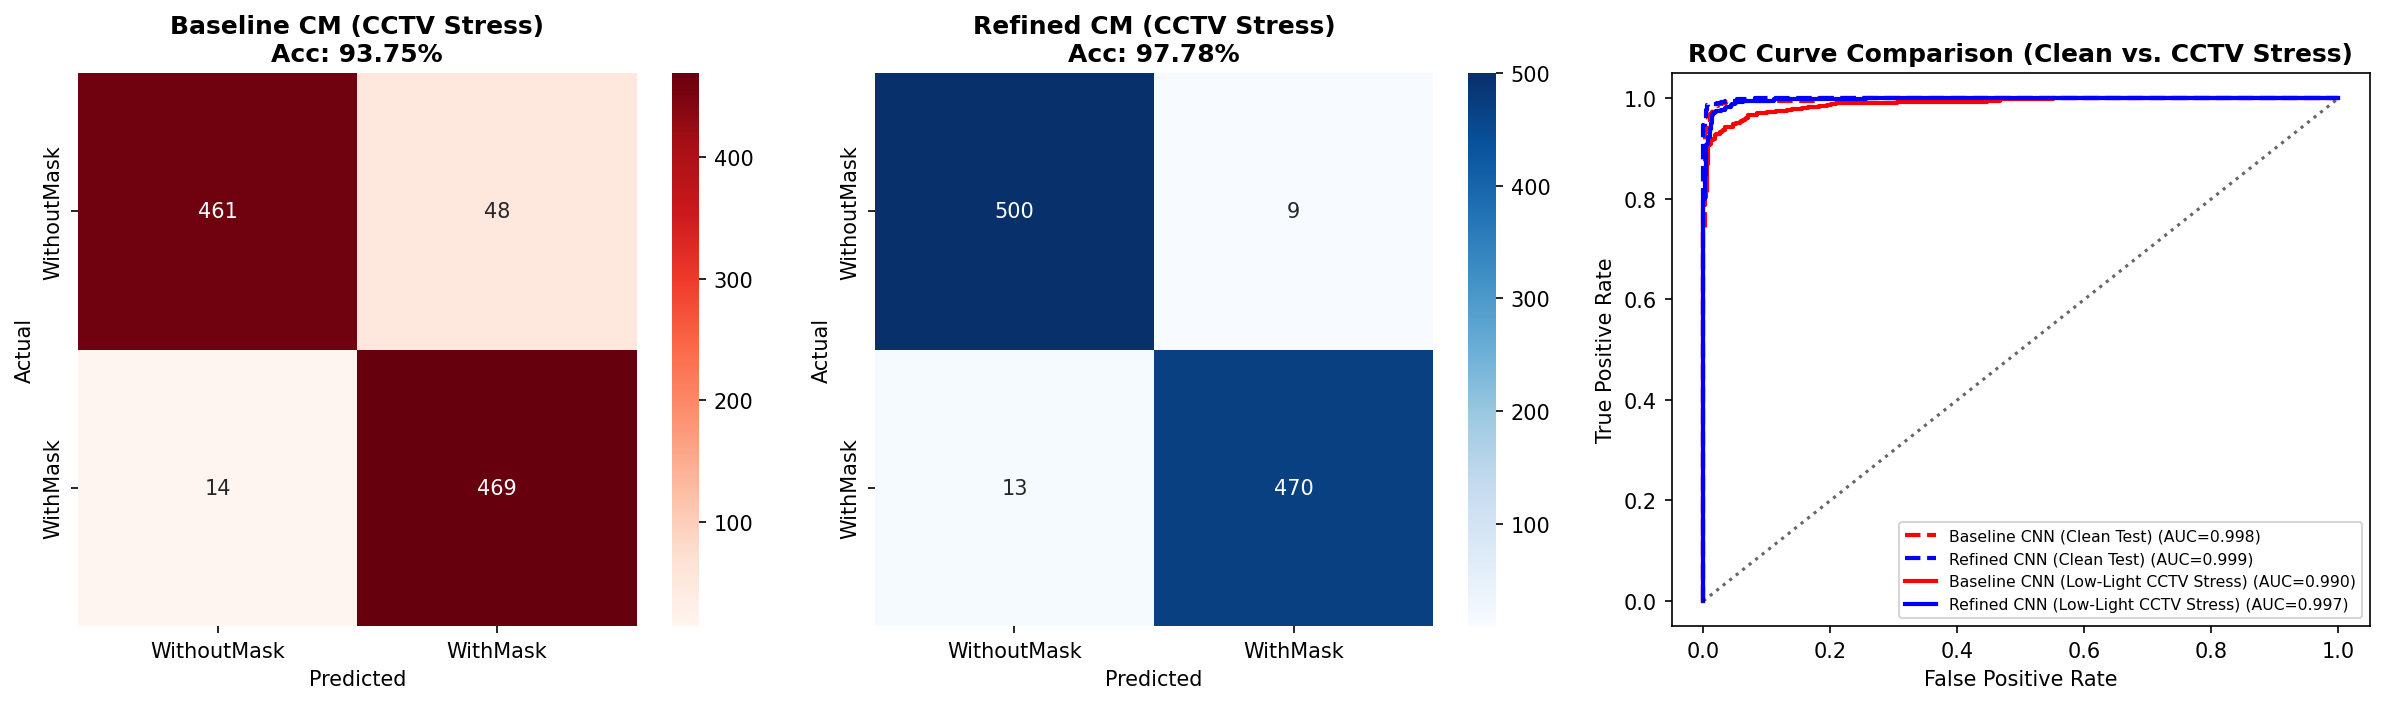

In [12]:
def collect_labels_and_images(dataset):
    imgs, lbls = [], []
    for x_batch, y_batch in dataset:
        imgs.append(x_batch.numpy())
        lbls.append(y_batch.numpy().ravel())
    return np.concatenate(imgs, axis=0), np.concatenate(lbls, axis=0).astype(int)

X_test_clean, y_test = collect_labels_and_images(test_ds_opt)
X_test_stress, _ = collect_labels_and_images(stress_test_ds_opt)

def evaluate_model(model, X_data, y_true, name):
    t_start = time.perf_counter()
    probs = model.predict(X_data, batch_size=BATCH_SIZE, verbose=0).ravel()
    elapsed_ms = (time.perf_counter() - t_start) * 1000.0 / len(y_true)
    preds = (probs >= 0.5).astype(int)
    metrics = {
        "model": name,
        "accuracy": accuracy_score(y_true, preds),
        "precision": precision_score(y_true, preds, zero_division=0),
        "recall": recall_score(y_true, preds, zero_division=0),
        "f1": f1_score(y_true, preds, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probs),
        "latency_ms": elapsed_ms,
        "cm": confusion_matrix(y_true, preds),
        "probs": probs,
        "preds": preds,
    }
    print(f"\n=== {name} ===")
    print(f"Accuracy: {metrics['accuracy']:.4f} | ROC-AUC: {metrics['roc_auc']:.4f} | Avg Inference: {elapsed_ms:.2f} ms/frame")
    print(classification_report(y_true, preds, target_names=CLASS_NAMES, digits=4))
    return metrics

res_base_clean = evaluate_model(baseline_model, X_test_clean, y_test, "Baseline CNN (Clean Test)")
res_ref_clean  = evaluate_model(refined_model,  X_test_clean, y_test, "Refined CNN (Clean Test)")
res_base_stress = evaluate_model(baseline_model, X_test_stress, y_test, "Baseline CNN (Low-Light CCTV Stress)")
res_ref_stress  = evaluate_model(refined_model,  X_test_stress, y_test, "Refined CNN (Low-Light CCTV Stress)")

# Plot Comparative Confusion Matrices (Stress Test) + ROC Curves
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=150)

sns.heatmap(
    res_base_stress["cm"], annot=True, fmt="d", cmap="Reds", ax=axes[0],
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
)
axes[0].set_title(f"Baseline CM (CCTV Stress)\nAcc: {res_base_stress['accuracy']*100:.2f}%", fontweight="bold")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    res_ref_stress["cm"], annot=True, fmt="d", cmap="Blues", ax=axes[1],
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
)
axes[1].set_title(f"Refined CM (CCTV Stress)\nAcc: {res_ref_stress['accuracy']*100:.2f}%", fontweight="bold")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

for res, style in [
    (res_base_clean, "r--"),
    (res_ref_clean, "b--"),
    (res_base_stress, "r-"),
    (res_ref_stress, "b-"),
]:
    fpr, tpr, _ = roc_curve(y_test, res["probs"])
    axes[2].plot(fpr, tpr, style, linewidth=2, label=f"{res['model']} (AUC={res['roc_auc']:.3f})")
axes[2].plot([0, 1], [0, 1], "k:", alpha=0.6)
axes[2].set_title("ROC Curve Comparison (Clean vs. CCTV Stress)", fontweight="bold")
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].legend(fontsize=7.5, loc="lower right")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig3_eval_comparison.png", dpi=200)
plt.show()

## 4.4 Model Explainability (Grad-CAM) and Misclassification Inspection
High accuracy can hide shortcut learning (for example, relying on shirt collars or background walls instead of the face). We apply **Grad-CAM** on the final convolutional activation (`last_conv`) of the refined CNN to verify that activation mass concentrates on the nose, mouth, and mask edges. Beneath the Grad-CAM visualisations, we inspect actual misclassified test images from the CCTV stress test to understand remaining failure modes.

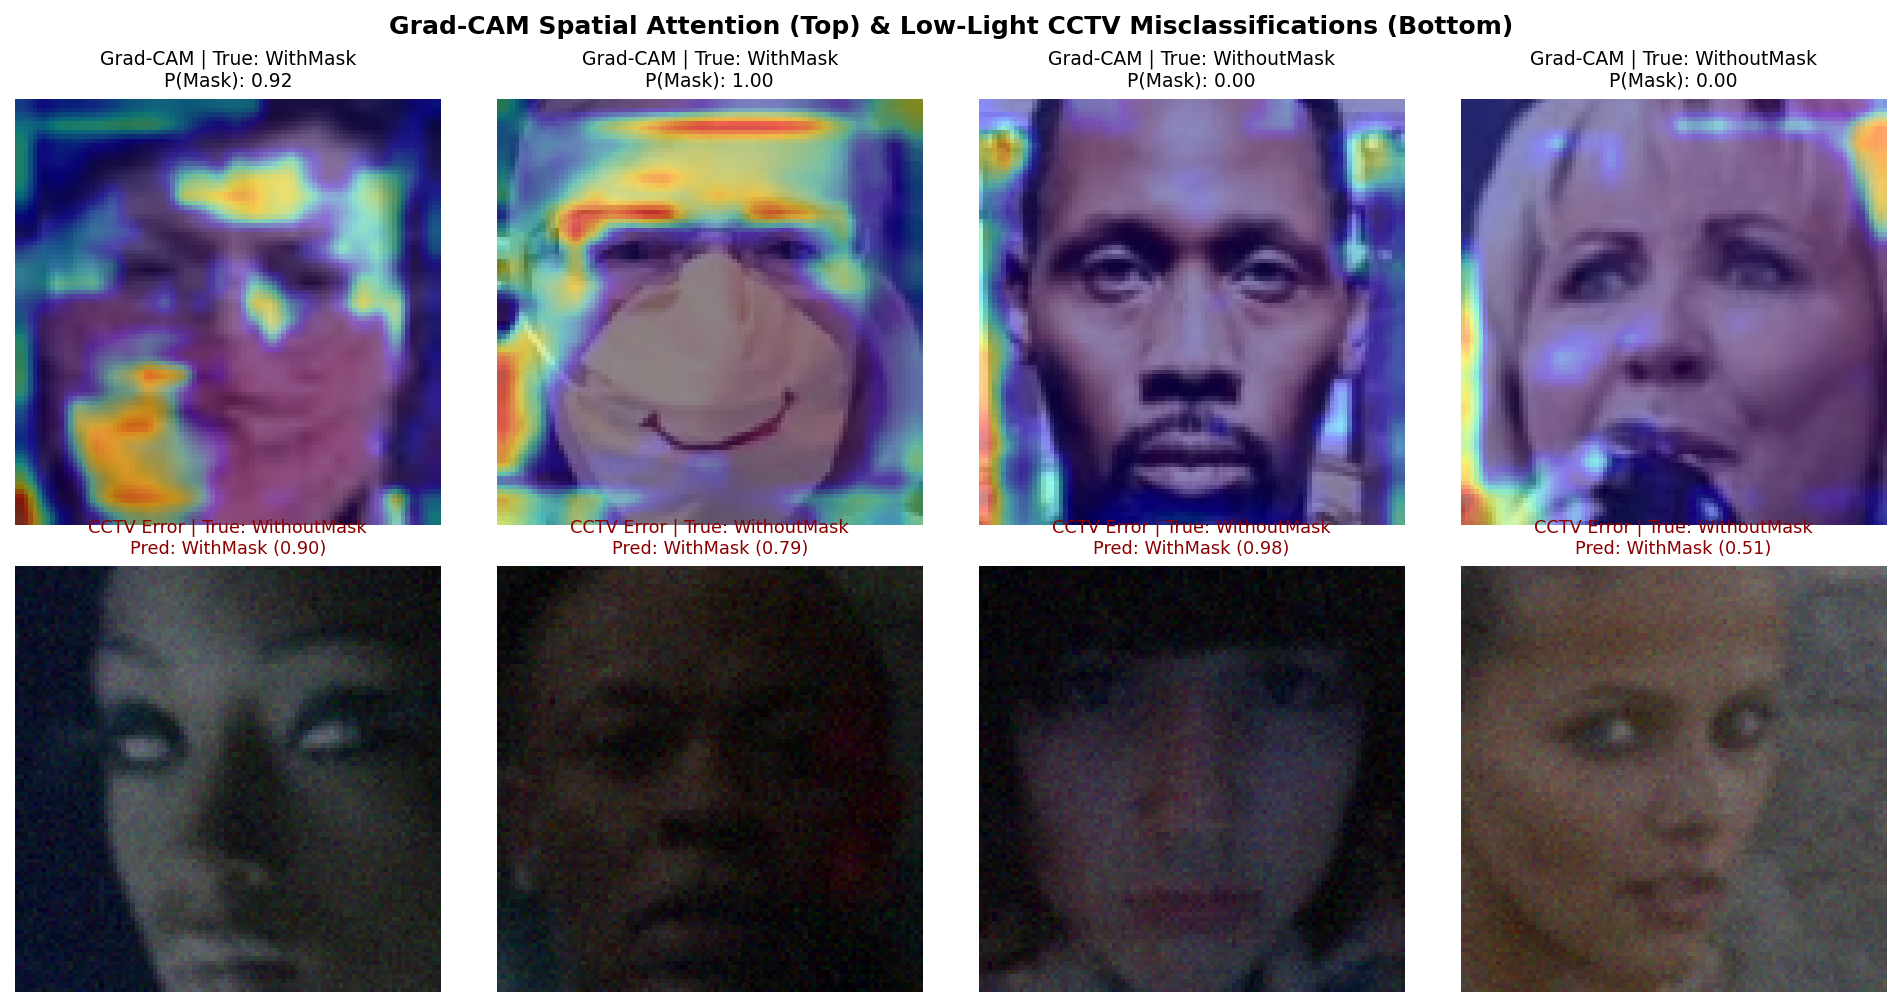

In [13]:
def make_gradcam_heatmap(img_batch, model, last_conv_layer_name="last_conv"):
    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output],
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_batch, training=False)
        score = predictions[:, 0]
    grads = tape.gradient(score, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

def overlay_gradcam(img_rgb_float, heatmap, alpha=0.45):
    img_uint8 = np.clip(img_rgb_float, 0, 255).astype(np.uint8)
    hm_resized = np.array(
        Image.fromarray(np.uint8(255 * heatmap)).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    ) / 255.0
    jet_rgb = (plt.cm.jet(hm_resized)[:, :, :3] * 255).astype(np.uint8)
    blended = np.clip((1 - alpha) * img_uint8 + alpha * jet_rgb, 0, 255).astype(np.uint8)
    return blended

# Top row: 4 Grad-CAM overlays (2 WithMask, 2 WithoutMask)
# Bottom row: Up to 4 actual misclassified stress-test images
masked_idx = np.where((y_test == 1) & (res_ref_clean["preds"] == 1))[0][:2]
clear_idx  = np.where((y_test == 0) & (res_ref_clean["preds"] == 0))[0][:2]
gradcam_indices = list(masked_idx) + list(clear_idx)

mis_indices = np.where(res_ref_stress["preds"] != y_test)[0]

fig, axes = plt.subplots(2, 4, figsize=(13, 6.8), dpi=150)

for i, idx in enumerate(gradcam_indices):
    img = X_test_clean[idx]
    hm = make_gradcam_heatmap(img[None, ...], refined_model, "last_conv")
    overlay = overlay_gradcam(img, hm)
    prob = res_ref_clean["probs"][idx]
    axes[0, i].imshow(overlay)
    axes[0, i].set_title(f"Grad-CAM | True: {CLASS_NAMES[y_test[idx]]}\nP(Mask): {prob:.2f}", fontsize=9)
    axes[0, i].axis("off")

for i in range(4):
    if i < len(mis_indices):
        idx = mis_indices[i]
        axes[1, i].imshow(np.clip(X_test_stress[idx], 0, 255).astype(np.uint8))
        axes[1, i].set_title(
            f"CCTV Error | True: {CLASS_NAMES[y_test[idx]]}\nPred: {CLASS_NAMES[res_ref_stress['preds'][idx]]} ({res_ref_stress['probs'][idx]:.2f})",
            fontsize=8.5,
            color="darkred",
        )
    else:
        axes[1, i].text(0.5, 0.5, "No further errors", ha="center", va="center")
    axes[1, i].axis("off")

plt.suptitle("Grad-CAM Spatial Attention (Top) & Low-Light CCTV Misclassifications (Bottom)", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig4_gradcam_errors.png", dpi=200)
plt.show()

## 4.5 Interactive Premises Inference Function & Report Sync Summary
To allow operational testing on any single camera frame, `predict_premises_frame()` loads an arbitrary image path, resizes it to `96 x 96`, computes the mask probability and inference latency, generates a Grad-CAM diagnostic overlay, and returns an actionable gate decision (`ACCESS_HOLD` vs `CLEAR_FOR_FACIAL_ID`). The final printout consolidates every exact metric from this run so the submitted PDF report stays 100% consistent with the code.

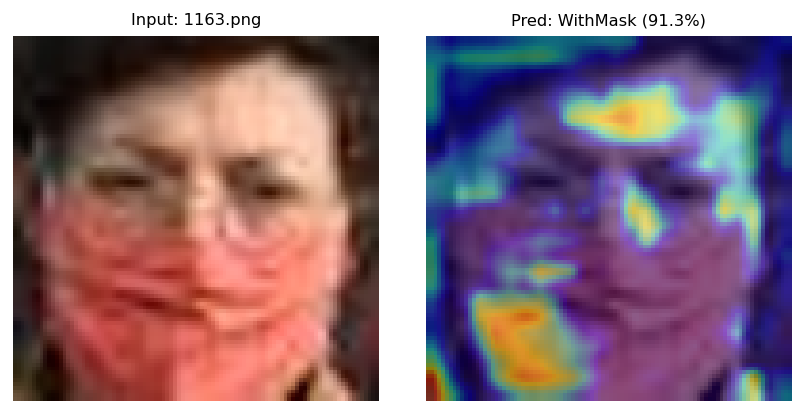

File       : 1163.png
Prediction : WithMask | P(Mask) = 91.26% | Latency = 302.0 ms
Gate Action: ACCESS_HOLD: Face obstructed — prompt visitor to remove mask or use access card



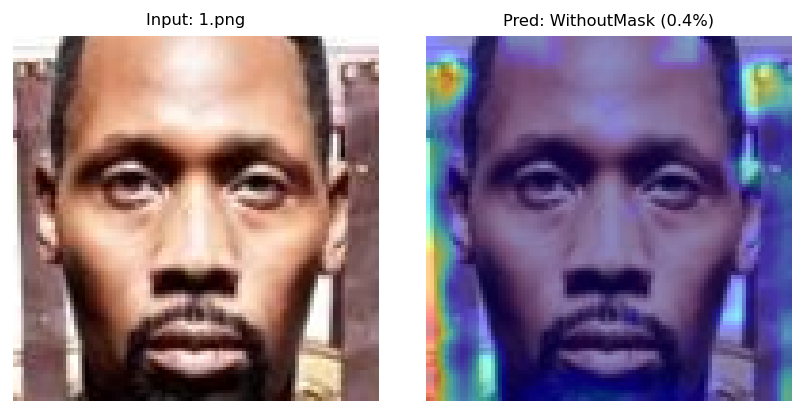

File       : 1.png
Prediction : WithoutMask | P(Mask) = 0.38% | Latency = 84.8 ms
Gate Action: CLEAR_FOR_FACIAL_ID: Unobstructed face — forward frame to recognition service

REPORT_SYNC_SUMMARY (EXACT VALUES FOR PDF REPORT)
Total Images Indexed : 11792 | Corrupt: 0

Split Breakdown:
     split       label  image_count
      Test    WithMask          483
      Test WithoutMask          509
     Train    WithMask         5000
     Train WithoutMask         5000
Validation    WithMask          400
Validation WithoutMask          400

Spark Class Pixel/Resolution Stats:
      label    n  min_w  max_w  avg_w  avg_h  avg_ratio  avg_brightness  std_brightness  avg_contrast  avg_r  avg_g  avg_b
   WithMask 5883     25    563  201.3  201.3        1.0          124.93           34.14         62.71 136.87 122.02 115.89
WithoutMask 5909     26    156  104.6  104.6        1.0          121.73           24.82         54.56 153.27 115.28  96.65

Baseline Params      : 1,273,025 | Train Time: 419.9s
Ref

In [14]:
def predict_premises_frame(image_path, threshold=0.50, show_plot=True):
    """Run premises occlusion pre-screening on any single image file."""
    path = Path(image_path)
    if not path.is_file():
        raise FileNotFoundError(f"Image not found: {path}")

    with Image.open(path) as im:
        img_resized = im.convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        arr = np.array(img_resized, dtype=np.float32)

    t0 = time.perf_counter()
    prob_mask = float(refined_model.predict(arr[None, ...], verbose=0)[0, 0])
    latency_ms = (time.perf_counter() - t0) * 1000.0

    is_masked = prob_mask >= threshold
    label = "WithMask" if is_masked else "WithoutMask"
    decision = (
        "ACCESS_HOLD: Face obstructed — prompt visitor to remove mask or use access card"
        if is_masked
        else "CLEAR_FOR_FACIAL_ID: Unobstructed face — forward frame to recognition service"
    )

    if show_plot:
        hm = make_gradcam_heatmap(arr[None, ...], refined_model, "last_conv")
        overlay = overlay_gradcam(arr, hm)
        fig, ax = plt.subplots(1, 2, figsize=(6.5, 3.2), dpi=130)
        ax[0].imshow(arr.astype(np.uint8))
        ax[0].set_title(f"Input: {path.name}", fontsize=9)
        ax[0].axis("off")
        ax[1].imshow(overlay)
        ax[1].set_title(f"Pred: {label} ({prob_mask*100:.1f}%)", fontsize=9)
        ax[1].axis("off")
        plt.tight_layout()
        plt.show()

    print(f"File       : {path.name}")
    print(f"Prediction : {label} | P(Mask) = {prob_mask*100:.2f}% | Latency = {latency_ms:.1f} ms")
    print(f"Gate Action: {decision}\n")
    return {"label": label, "prob_mask": prob_mask, "latency_ms": latency_ms, "decision": decision}

# Interactive smoke test on one real masked image and one unmasked test image
sample_masked_path = meta_pd[(meta_pd["split"] == "Test") & (meta_pd["label"] == "WithMask")].iloc[0]["filepath"]
sample_clear_path  = meta_pd[(meta_pd["split"] == "Test") & (meta_pd["label"] == "WithoutMask")].iloc[0]["filepath"]

out_1 = predict_premises_frame(sample_masked_path, show_plot=True)
out_2 = predict_premises_frame(sample_clear_path, show_plot=True)

# Exact Report Sync Summary (paste these exact numbers into Section 5 of the PDF report)
print("=" * 72)
print("REPORT_SYNC_SUMMARY (EXACT VALUES FOR PDF REPORT)")
print("=" * 72)
print(f"Total Images Indexed : {total_images} | Corrupt: {corrupt_count}")
print("\nSplit Breakdown:")
print(split_summary_pd.to_string(index=False))
print("\nSpark Class Pixel/Resolution Stats:")
print(class_stats_pd.to_string(index=False))
print(f"\nBaseline Params      : {baseline_model.count_params():,} | Train Time: {baseline_train_time:.1f}s")
print(f"Refined Params       : {refined_model.count_params():,} | Train Time: {refined_train_time:.1f}s | Best Epoch: {best_refined_epoch}")

summary_rows = []
for r in [res_base_clean, res_ref_clean, res_base_stress, res_ref_stress]:
    tn, fp, fn, tp = r["cm"].ravel()
    summary_rows.append({
        "Evaluation": r["model"],
        "Acc (%)": round(r["accuracy"] * 100, 2),
        "Prec": round(r["precision"], 4),
        "Rec": round(r["recall"], 4),
        "F1": round(r["f1"], 4),
        "AUC": round(r["roc_auc"], 4),
        "TN/FP/FN/TP": f"{tn}/{fp}/{fn}/{tp}",
        "ms/img": round(r["latency_ms"], 2),
    })
print("\nModel Evaluation Summary:")
print(pd.DataFrame(summary_rows).to_string(index=False))
print("=" * 72)